# Deflection of a membrane

This tutorial follows the chapter on the membrane problem in the
[FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/).
A thin elastic membrane is clamped along the rim of the unit disk $\Omega$ and loaded by a
pressure $p$.  Its deflection $w$ solves the Poisson problem

$$ -\Delta w = p \quad \text{in } \Omega, \qquad w = 0 \quad \text{on } \partial\Omega , $$

where the (scaled) load is a narrow Gaussian bump centred at $(0, R_0)$,

$$ p(x, y) = 4 \exp\!\big(-\beta^2 (x^2 + (y - R_0)^2)\big), \qquad \beta = 8,\ R_0 = 0.6 . $$

New compared to the Poisson tutorial: the domain is not a unit square but a disk, so we
have to build a mesh ourselves, and the boundary is curved.

## Geometry and mesh

`Mesh` accepts any Netgen mesh.  We describe the disk with the OpenCASCADE interface of
Netgen, name its boundary `"rim"` and generate a triangulation.  Calling `.curve(3)`
maps the elements next to the boundary onto the exact circle with cubic polynomials, so
the geometry is not approximated by straight edges.

boundaries: ('rim',)


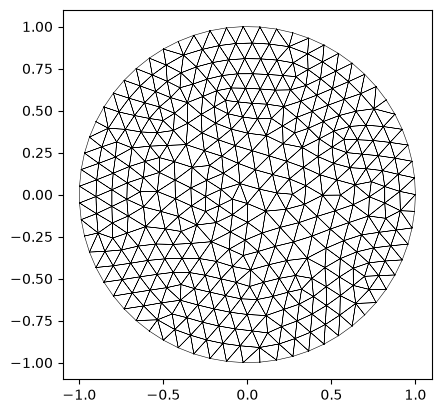

In [1]:
from netgen.occ import Circle, OCCGeometry
from ngsufl import *

disk = Circle((0, 0), 1).Face()
disk.edges.name = "rim"
ngmesh = OCCGeometry(disk, dim=2).GenerateMesh(maxh=0.1)
mesh = Mesh(ngmesh).curve(3)

print("boundaries:", mesh.boundaries)
plot(mesh, lw=0.4).set_aspect("equal");

## Variational problem

The weak form is the same as for the Poisson equation.  The load is written as a UFL
expression of the `SpatialCoordinate`.

In [2]:
V = FunctionSpace(mesh, "Lagrange", 2)
w, v = TrialFunction(V), TestFunction(V)
x = SpatialCoordinate(mesh)

beta, R0 = 8.0, 0.6
p = 4 * exp(-beta**2 * (x[0]**2 + (x[1] - R0)**2))

a = inner(grad(w), grad(v)) * dx
L = p * v * dx

wh = Function(V, name="w")
solve(a == L, wh, DirichletBC(V, 0.0, "rim"))
print("dofs:", V.dim())

dofs: 1438


## Plot of the deflection

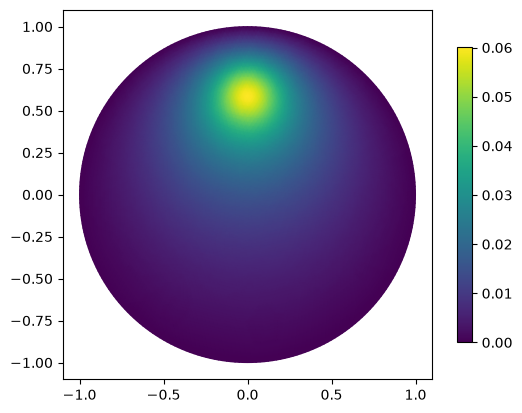

In [3]:
ax = plot(wh)
ax.set_aspect("equal");

## Deflection and load along a line

To compare the deflection with the load we evaluate both at points on the line
$x = 0$.  A `Function` can be called at a point; a UFL expression is first turned into
a Function by interpolation.  The two quantities live on very different scales, so
they get separate axes.

max deflection on the line: 0.06019400231168266


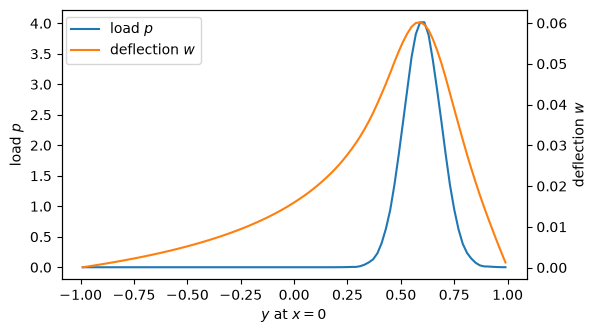

In [4]:
import numpy as np
import matplotlib.pyplot as plt

ph = Function(V).interpolate(p)
ys = np.linspace(-0.99, 0.99, 100)
w_line = [wh.at(0.0, y) for y in ys]
p_line = [ph.at(0.0, y) for y in ys]
print("max deflection on the line:", max(w_line))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ys, p_line, "C0", label="load $p$")
ax.set_xlabel("$y$ at $x = 0$")
ax.set_ylabel("load $p$")
ax2 = ax.twinx()
ax2.plot(ys, w_line, "C1", label="deflection $w$")
ax2.set_ylabel("deflection $w$")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88));

## Checks

Two checks.  First, for a constant load $p = 1$ the exact solution on the disk is
$w = (1 - r^2)/4$.  On the curved mesh the error is small, which is only possible when
the boundary is represented accurately.  Second, we repeat the Gaussian-load
computation with plain NGSolve and compare the two deflections.

In [5]:
r2 = x[0]**2 + x[1]**2
w_exact = (1 - r2) / 4
w1 = Function(V)
solve(a == Constant(1.0) * v * dx, w1, DirichletBC(V, 0.0, "rim"))
print("constant load, L2 error vs (1-r^2)/4:", errornorm(w_exact, w1))

constant load, L2 error vs (1-r^2)/4: 1.91831656030419e-06


In [6]:
import ngsolve as ngs

m = mesh.ngs
fes = ngs.H1(m, order=2, dirichlet="rim")
u, vt = fes.TnT()
cx, cy = ngs.x, ngs.y
load = 4 * ngs.exp(-beta**2 * (cx**2 + (cy - R0)**2))
A = ngs.BilinearForm(ngs.grad(u) * ngs.grad(vt) * ngs.dx).Assemble()
F = ngs.LinearForm(load * vt * ngs.dx).Assemble()
gf = ngs.GridFunction(fes)
gf.vec.data = A.mat.Inverse(fes.FreeDofs()) * F.vec

diff_ = ngs.sqrt(ngs.Integrate((gf - to_cf(wh))**2, m))
print("difference to native NGSolve (L2):", diff_)  # only quadrature differs

difference to native NGSolve (L2): 2.8811763128061095e-07
